# Fase 5 — ETS A/N/A versus Seasonal Naive

**Somente train; eval congelado. 50.000 séries × quatro folds × sete dias.**

Candidato fixado antes dos resultados: sem tendência, sazonalidade aditiva semanal; SLSQP, maxiter=200, ftol=1e-6, use_brute=False, remove_bias=False.

Este notebook consome os outputs de `scripts/run_statistical_forecast.py`; não ajusta modelos. A lógica está em src. Target = venda observada normalizada, não demanda latente. Relatório completo: `docs/statistical_forecasting_report.md`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from src.reporting.statistical_plots import load_outputs, PLOTS, save_figure
data = load_outputs(root)
assert data['summary']['source_split'] == 'train'
assert data['summary']['analysis_view'] == 'prospective'
display(pd.DataFrame(data['summary']['folds']))
display(data['metrics'].loc[data['metrics'].level.eq('global'), ['model','n_forecasts','actual_sum','mae','rmse','wape','bias','bias_pct']])

,fold_id,forecast_origin,cutoff_date,history_start,history_end,history_days,test_start,test_end,n_series,xyz_thresholds,exposure_thresholds,xyz_counts,abc_product_counts,exposure_counts,censoring_risk_count,undefined_pattern_count,no_stockout_history_count,complete_weeks
0,1,2024-05-29,2024-05-28,2024-03-28,2024-05-28,62,2024-05-29,2024-06-04,50000,"{'name': 'weekly_median_tail', 'variability_me...","{'low_quantile': 0.25, 'high_quantile': 0.75, ...","{'X': 13208, 'Y': 15851, 'Z': 20941}","{'A': 124, 'B': 167, 'C': 574}","{'HIGH': 12779, 'LOW': 12680, 'MEDIUM': 24541}",3727,7,2,[8]
1,2,2024-06-05,2024-06-04,2024-03-28,2024-06-04,69,2024-06-05,2024-06-11,50000,"{'name': 'weekly_median_tail', 'variability_me...","{'low_quantile': 0.25, 'high_quantile': 0.75, ...","{'X': 13199, 'Y': 15867, 'Z': 20934}","{'A': 124, 'B': 167, 'C': 574}","{'HIGH': 13861, 'LOW': 12542, 'MEDIUM': 23597}",3314,4,1,[9]
2,3,2024-06-12,2024-06-11,2024-03-28,2024-06-11,76,2024-06-12,2024-06-18,50000,"{'name': 'weekly_median_tail', 'variability_me...","{'low_quantile': 0.25, 'high_quantile': 0.75, ...","{'X': 13437, 'Y': 15627, 'Z': 20936}","{'A': 124, 'B': 167, 'C': 574}","{'HIGH': 12805, 'LOW': 13807, 'MEDIUM': 23388}",3061,4,0,[10]
3,4,2024-06-19,2024-06-18,2024-03-28,2024-06-18,83,2024-06-19,2024-06-25,50000,"{'name': 'weekly_median_tail', 'variability_me...","{'low_quantile': 0.25, 'high_quantile': 0.75, ...","{'X': 13185, 'Y': 15821, 'Z': 20994}","{'A': 123, 'B': 167, 'C': 575}","{'HIGH': 13288, 'LOW': 12871, 'MEDIUM': 23841}",3209,4,0,[11]


,model,n_forecasts,actual_sum,mae,rmse,wape,bias,bias_pct
36,ets_ana,1400000,1518029.667,0.390632,0.672312,0.360260,-0.023541,-0.021711
37,seasonal_naive,1400000,1518029.667,0.458587,0.775595,0.422931,-0.035451,-0.032695


## 01. Erros globais

Métricas consolidadas por somas; mesma cobertura e denominador. Fallback, se houver, integra o candidato solicitado.

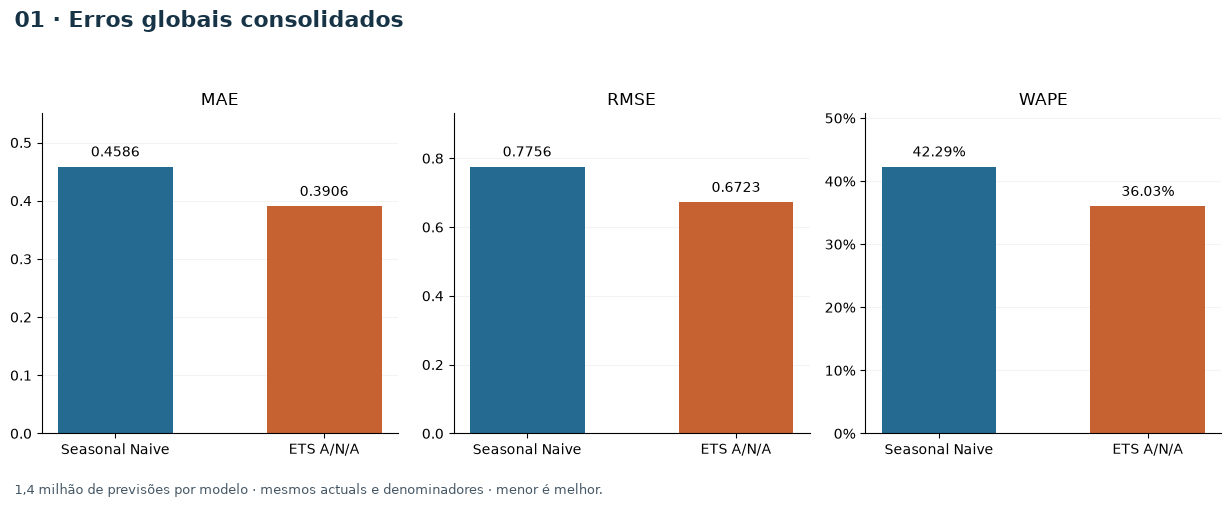

In [2]:
fig = PLOTS[0](data)
save_figure(fig, 1, root)
display(fig)
plt.close(fig)

## 02. Comparação por fold

Quatro janelas sem sobreposição. WAPE e bias são mostrados juntos para explicitar tradeoffs.

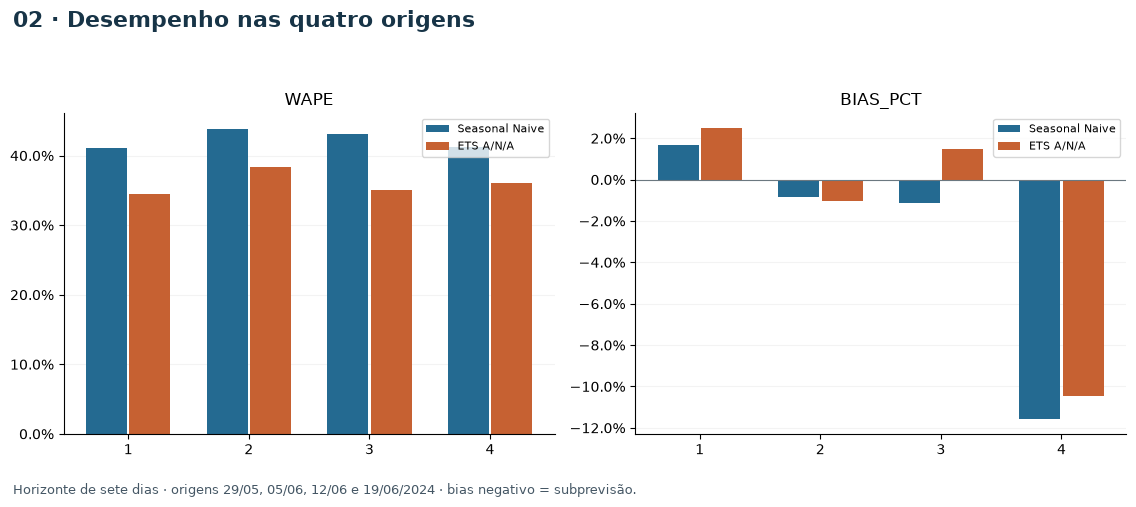

In [3]:
fig = PLOTS[1](data)
save_figure(fig, 2, root)
display(fig)
plt.close(fig)

## 03. ABC

Contribuição do produto conhecida até cada corte. Escala muda a leitura de MAE e WAPE.

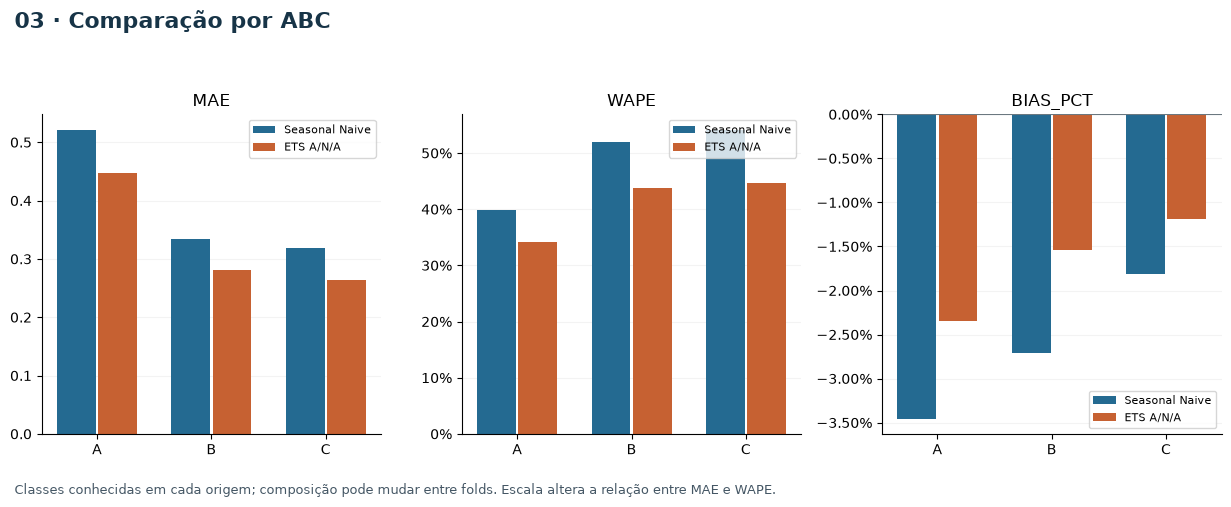

In [4]:
fig = PLOTS[2](data)
save_figure(fig, 3, root)
display(fig)
plt.close(fig)

## 04. XYZ

Classes prospectivas preservadas da Fase 4; não foram redefinidas para favorecer ETS.

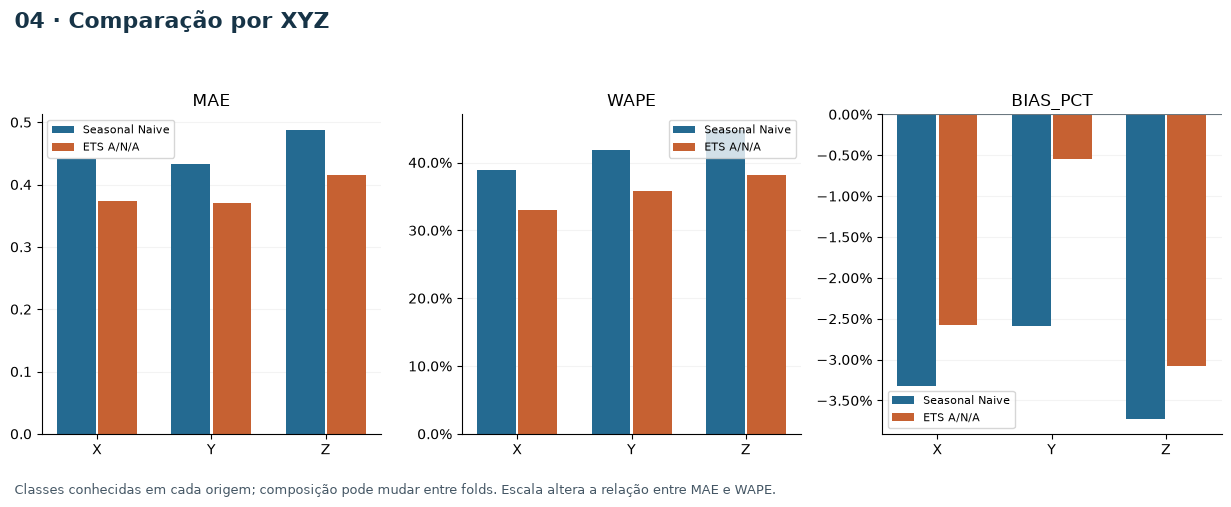

In [5]:
fig = PLOTS[3](data)
save_figure(fig, 4, root)
display(fig)
plt.close(fig)

## 05. ABC × XYZ

Melhoria = (Seasonal Naive − ETS) / Seasonal Naive. Referência zero produz nulo. Não aplicar a bias assinado.

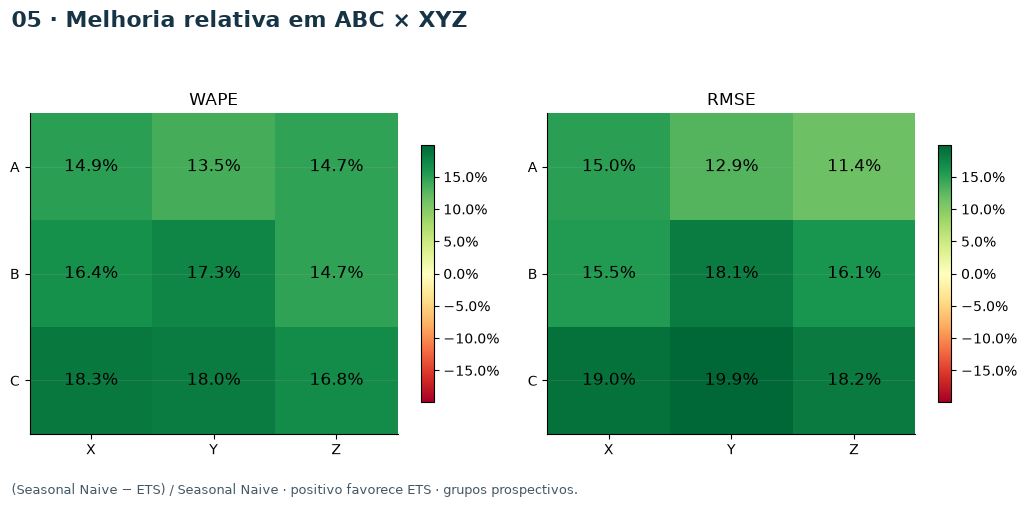

In [6]:
fig = PLOTS[4](data)
save_figure(fig, 5, root)
display(fig)
plt.close(fig)

## 06. Exposição e flag

Associações com disponibilidade, sem efeito causal identificado ou estimativa de demanda perdida.

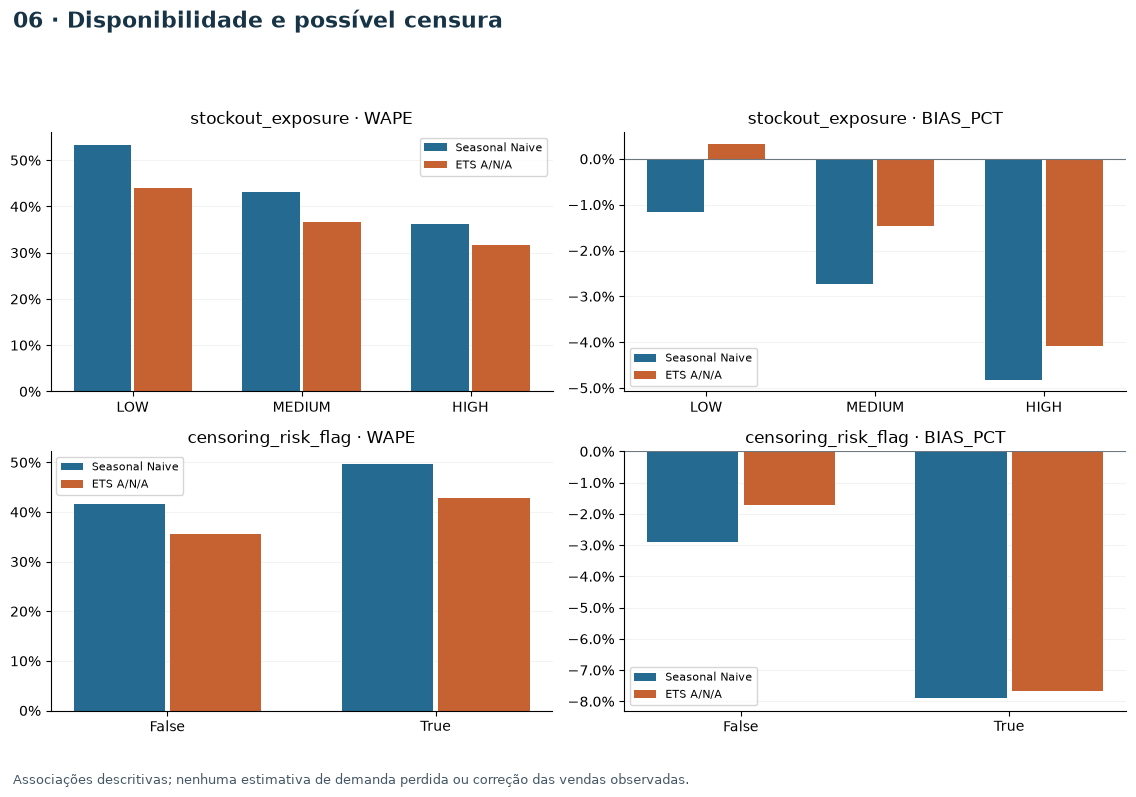

In [7]:
fig = PLOTS[5](data)
save_figure(fig, 6, root)
display(fig)
plt.close(fig)

## 07. Distribuição de bias

Os 28 dias são agregados por série antes dos quantis. Cada série tem peso igual; bias negativo representa subprevisão.

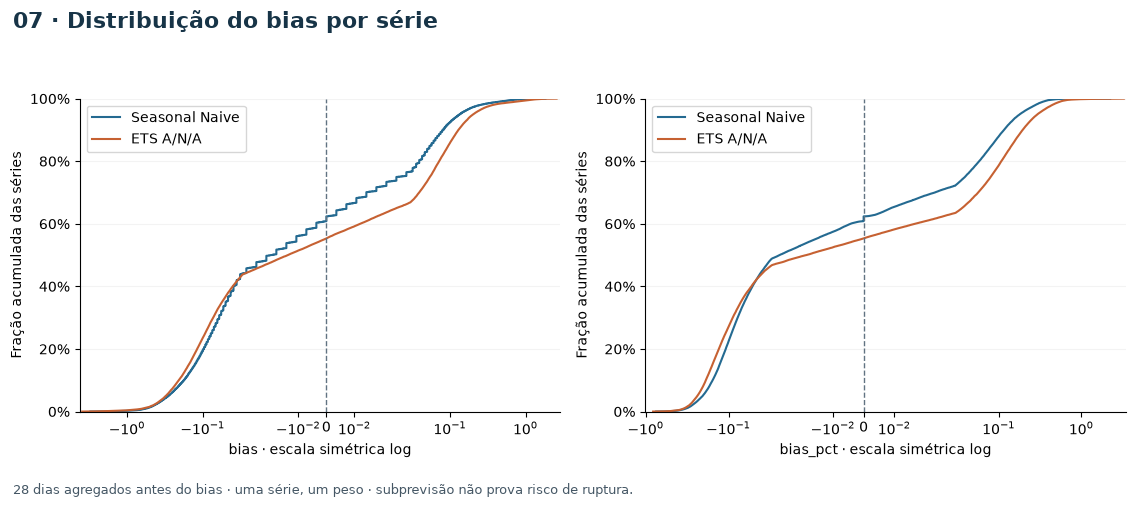

In [8]:
fig = PLOTS[6](data)
save_figure(fig, 7, root)
display(fig)
plt.close(fig)

## 08. Win rate e materialidade

Win rate pareado; tolerância atol=1e-12, rtol=1e-10. Em ABC/XYZ, agregam-se apenas os folds em que cada classe era conhecida; uma série pode aparecer em classes diferentes. As tabelas abaixo incluem os limiares descritivos solicitados.

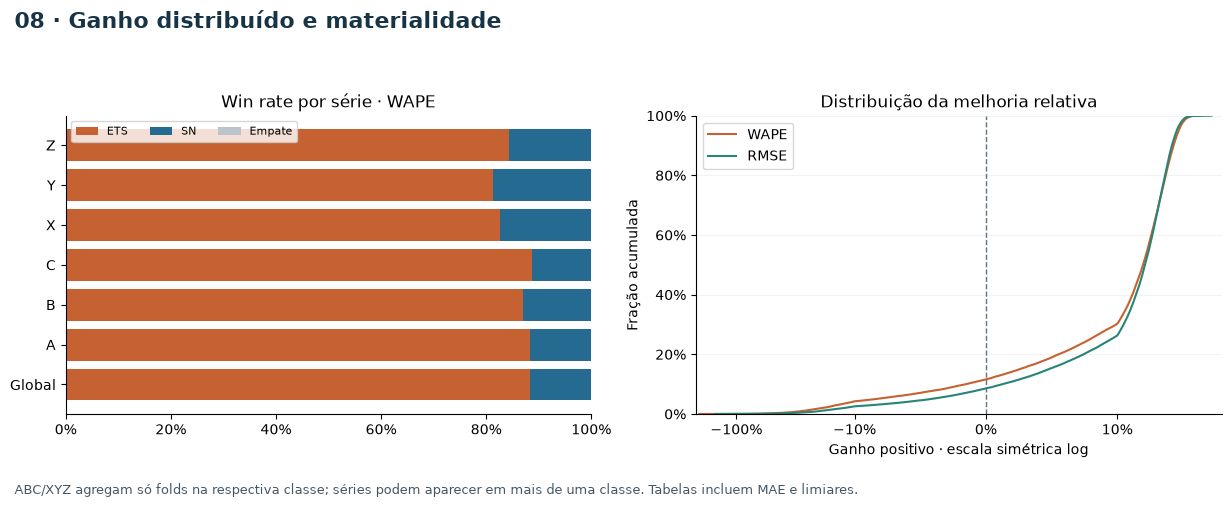

,level,segment,metric,n_series_cases,valid_cases,undefined_cases,min_folds,max_folds,ets_count,ets_rate,seasonal_naive_count,seasonal_naive_rate,tie_count,tie_rate
0,global,ALL,mae,50000,50000,0,4,4,44203,0.884060,5797,0.115940,0,0.0
1,global,ALL,wape,50000,50000,0,4,4,44203,0.884060,5797,0.115940,0,0.0
2,abc,A,mae,33841,33841,0,1,4,29872,0.882716,3969,0.117284,0,0.0
3,abc,A,wape,33841,33841,0,1,4,29872,0.882716,3969,0.117284,0,0.0
4,abc,B,mae,12556,12556,0,1,4,10930,0.870500,1626,0.129500,0,0.0
5,abc,B,wape,12556,12556,0,1,4,10930,0.870500,1626,0.129500,0,0.0
6,abc,C,mae,4629,4629,0,1,4,4106,0.887017,523,0.112983,0,0.0
7,abc,C,wape,4629,4629,0,1,4,4106,0.887017,523,0.112983,0,0.0
8,xyz,X,mae,19805,19805,0,1,4,16369,0.826508,3436,0.173492,0,0.0
9,xyz,X,wape,19805,19803,2,1,4,16369,0.826592,3434,0.173408,0,0.0


,metric,total_series,valid_series,undefined_reference,p25,median,p75,positive_fraction,improvement_ge_01,decline_le_minus_01,improvement_ge_05,decline_le_minus_05,improvement_ge_10,decline_le_minus_10
0,mae,50000,50000,0,0.079037,0.165314,0.240271,0.88406,0.87176,0.10530,0.81052,0.07086,0.69802,0.04256
1,rmse,50000,50000,0,0.095127,0.172075,0.238379,0.91440,0.90314,0.07548,0.84622,0.04570,0.73696,0.02560
2,wape,50000,50000,0,0.079037,0.165314,0.240271,0.88406,0.87176,0.10530,0.81052,0.07086,0.69802,0.04256


In [9]:
fig = PLOTS[7](data)
save_figure(fig, 8, root)
display(fig)
plt.close(fig)
display(data['win_rates'])
display(data['materiality'])

## 09. Fallback e clipping

Fallback é uma decisão por ajuste. Clipping é projeção de forecast negativo em zero, preservando seu valor original; não é falha.

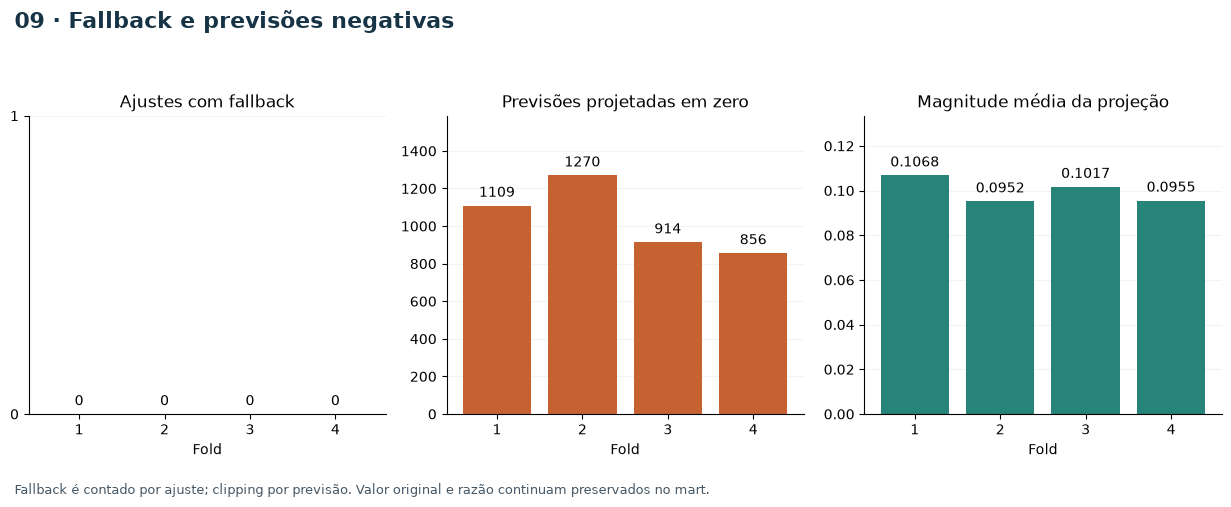

,level,fold_id,abc_class,xyz_class,stockout_exposure,censoring_risk_flag,n_forecasts,n_fits,fallback_fits,clipped_forecasts,clipped_fits,minimum_unclipped,mean_clip_magnitude,total_upward_projection,fallback_rate,clipping_rate
0,global,NaN,NaN,NaN,NaN,None,1400000,200000,0,4149,2191,-1.091927,0.099808,414.104775,0.0,0.002964
1,fold,1.0,NaN,NaN,NaN,None,350000,50000,0,1109,566,-0.931073,0.106814,118.457181,0.0,0.003169
2,fold,2.0,NaN,NaN,NaN,None,350000,50000,0,1270,637,-0.809988,0.095200,120.903740,0.0,0.003629
3,fold,3.0,NaN,NaN,NaN,None,350000,50000,0,914,472,-1.027349,0.101707,92.959763,0.0,0.002611
4,fold,4.0,NaN,NaN,NaN,None,350000,50000,0,856,516,-1.091927,0.095542,81.784092,0.0,0.002446


In [10]:
fig = PLOTS[8](data)
save_figure(fig, 9, root)
display(fig)
plt.close(fig)
display(data['fit_diagnostics'].loc[data['fit_diagnostics'].level.isin(['global','fold'])])

## 10. Exemplos reproduzíveis

Extremos do último fold, desempate por loja/produto. Ganho/piora por WAPE e variação do bias. Fallback, se existir, usa a origem mais recente disponível. Exemplos não representam a população nem selecionam modelos.

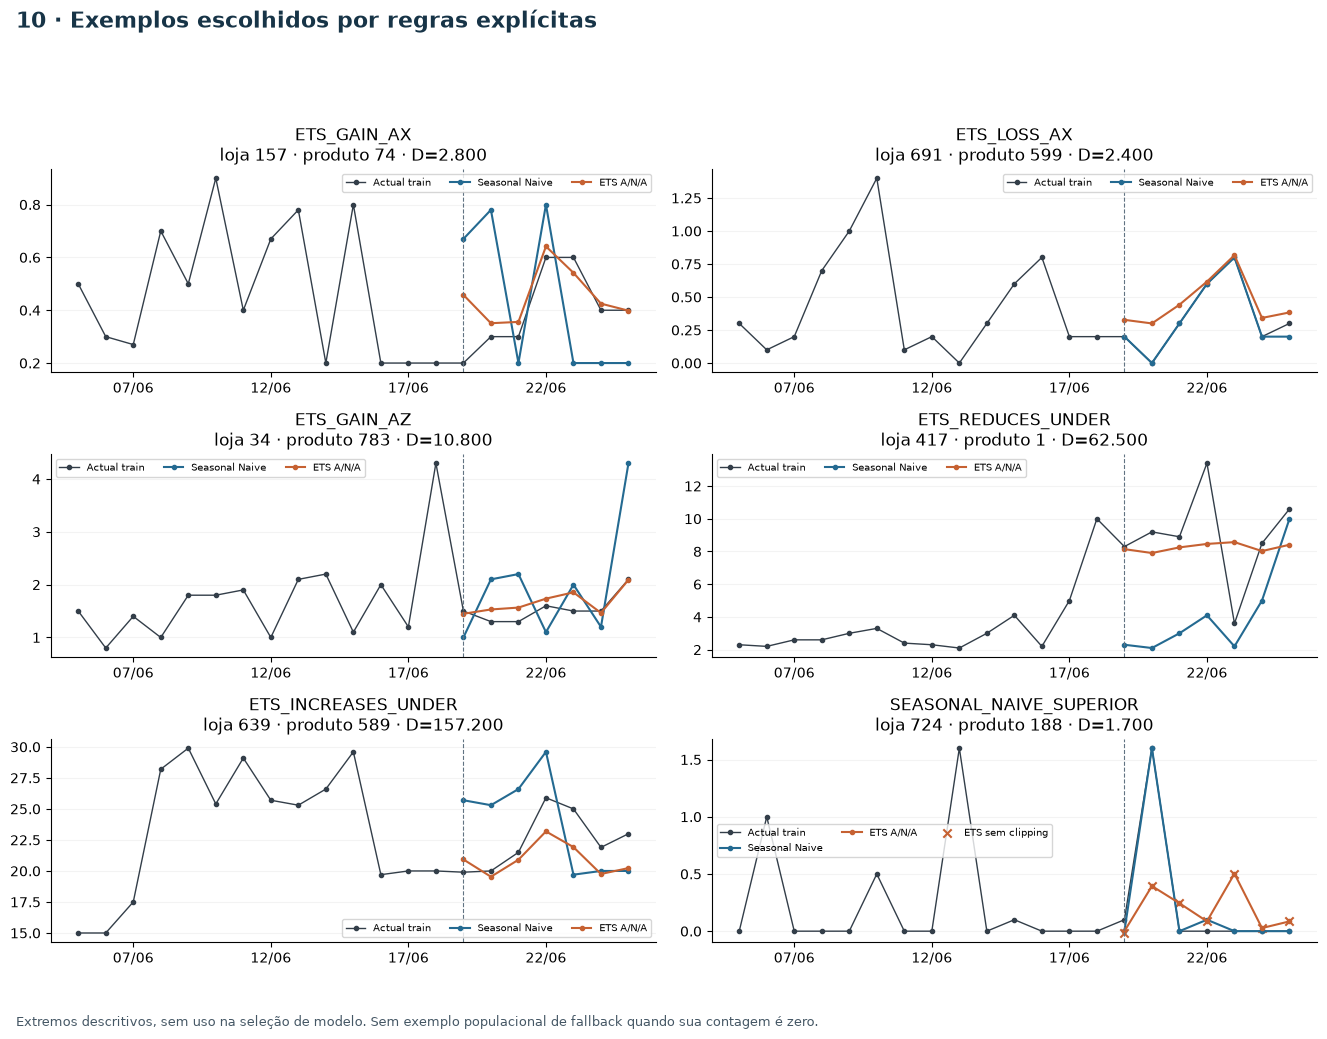

In [11]:
fig = PLOTS[9](data)
save_figure(fig, 10, root)
display(fig)
plt.close(fig)

## Potencial híbrido e limites

Análise predefinida antes dos resultados: usar ETS no segmento ABC×XYZ somente após pelo menos dois folds passados, todos com melhoria em WAPE, sem perda em RMSE e sem piora do bias absoluto consolidado. Os dois primeiros folds usam SN. A classe do fold corrente vem de seu snapshot prospectivo. Nenhum erro do próprio fold decide a escolha. Não é política operacional final.

Quatro folds e 28 dias de avaliação não garantem generalização. Não há MAPE, tuning, correção de censura ou uso de eval. Métricas percentuais com D=0 ficam nulas; nenhum caso é removido dos erros absolutos. Reprodução inclui contratos, hashes e pequena amostra de ajustes, sem segunda execução populacional.

**Classificação da evidência: A — ETS claramente superior neste backtest.** Ganho global de MAE/WAPE de 14,82% e RMSE de 13,32%, nos quatro folds e em todos os segmentos predefinidos. Bias global melhora de −3,27% para −2,17%, mas a distribuição por série se alarga; a magnitude do bias piora nos folds 1, 2 e 3. ETS vence MAE/WAPE em 88,406% das séries; 4,256% pioram pelo menos 10%. A regra híbrida conservadora melhora WAPE em apenas 2,15% sobre SN e fica atrás de ETS uniforme. Conclusão restrita ao backtest observado; não é adoção operacional nem garantia no holdout.

In [12]:
display(pd.DataFrame(data['summary']['hybrid_metrics']))
display(pd.DataFrame(data['summary']['denominator_diagnostics']))
from src.forecasting.backtesting import peak_working_set_bytes
from src.forecasting.statistical_backtesting import write_json
write_json(root / 'data/outputs/statistical_forecasting/notebook_kernel_performance.json', {'peak_working_set_bytes': peak_working_set_bytes(), 'scope': 'notebook kernel only'})

,level,fold_id,mae,rmse,wape,bias,bias_pct,actual_sum,n_forecasts
0,fold,1.0,0.426069,0.729601,0.410795,0.017375,0.016752,363013.688,350000
1,fold,2.0,0.458965,0.785785,0.438804,-0.008763,-0.008379,366080.901,350000
2,fold,3.0,0.444995,0.739622,0.420704,-0.011087,-0.010482,370208.823,350000
3,fold,4.0,0.464930,0.782436,0.388620,-0.134649,-0.112549,418726.255,350000
4,global,NaN,0.448740,0.759773,0.413849,-0.034281,-0.031616,1518029.667,1400000


,level,n_pairs,zero_denominator_pairs,minimum_positive_actual_sum,zero_reference_mae,undefined_improvement_wape
0,series,50000,0,1.1,0,0
1,series_fold,200000,263,0.1,16,264
